In [5]:
# Load the libraries used in this lab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Splitting the data, cross-validation, and the model itself
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.metrics import roc_curve, roc_auc_score

In [6]:
#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)


{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [7]:
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [8]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [9]:
print(bank_df.job.unique())
print(bank_df.marital.unique())
print(bank_df.education.unique())

['management' 'technician' 'entrepreneur' 'blue-collar' nan 'retired'
 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid' 'student']
['married' 'single' 'divorced']
['tertiary' 'secondary' nan 'primary']


In [10]:
print(bank_df.head())

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome   y  
0     NaN            5   may       261         1     -1         0      NaN  no  
1     NaN            5   may       151         1     -1         0      NaN  no  
2     NaN            5   may        76         1     -1         0      NaN  no  
3     NaN            5   may        92         1     -1         0      NaN  no  
4     NaN            5   may       198         1     -1         0      NaN  no  


In [11]:
#Check missing values
missing_count = bank_df.isnull().sum()
#find the missing percentage of each varible
missing_percent = bank_df.isnull().mean()*100
#convert missing value and percentage into a table
missing_summary = pd.DataFrame({'missing_count': missing_count, 'missing_percent': missing_percent})
missing_summary

,missing_count,missing_percent
age,0,0.000000
job,288,0.637013
marital,0,0.000000
education,1857,4.107407
default,0,0.000000
balance,0,0.000000
housing,0,0.000000
loan,0,0.000000
contact,13020,28.798301
day_of_week,0,0.000000


In [12]:
#check exact duplicate rows
duplicate_count= bank_df.duplicated().sum()
print(duplicate_count)

0


In [13]:

# Create a separate dataset for descriptive analysis
clean_bankdf = bank_df.copy()

# Remove duration because it is not relevant to our descriptive question
clean_bankdf = clean_bankdf.drop(columns=["duration"])

# Check remaining columns
print(clean_bankdf.shape)
print(clean_bankdf.columns.tolist())


(45211, 16)
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [14]:

# Restore unknown categorical values

unknown_cols = [
    "job",
    "education",
    "contact",
    "poutcome"
]

for col in unknown_cols:
    clean_bankdf[col] = clean_bankdf[col].fillna("unknown")

# Check remaining missing values
print(clean_bankdf.isnull().sum())


age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64


In [15]:

# Check relationship between previous and poutcome

pd.crosstab(
    clean_bankdf["previous"] > 0,
    clean_bankdf["poutcome"]
)

poutcome,failure,other,success,unknown
previous,,,,
False,0,0,0,36954
True,4901,1840,1511,5


Here, we found out that that poutcome = unknown, it does not necessarily equal to previous = 0, which are those who are not contacted previously.

Descriptive Modeling : How can the bank use historical campaign performance and contact frequency patterns to better allocate its marketing resources across customer groups?

In [16]:
#Convert subscription outcome to binary --> so we could use means to calculate subscription rate
clean_bankdf["subscribed"] = clean_bankdf["y"].map({
    "yes": 1,
    "no": 0
})

# Check the new variable
print(clean_bankdf["subscribed"].value_counts())

# Calculate overall subscription rate
print(
    "Overall subscription rate:",
    clean_bankdf["subscribed"].mean() * 100
)


subscribed
0    39922
1     5289
Name: count, dtype: int64
Overall subscription rate: 11.698480458295547


In [17]:
#Create previous_contact binary grouping to find out the historical contact history.
import numpy as np

clean_bankdf["previous_contact"] = np.where(
    clean_bankdf["previous"] > 0,
    "Previously contacted",
    "Never contacted"
)

# Check the number of observations in each group
print(clean_bankdf["previous_contact"].value_counts())

# Verify the grouping is correct
print(
    pd.crosstab(
        clean_bankdf["previous"] > 0,
        clean_bankdf["previous_contact"]
    )
)

previous_contact
Never contacted         36954
Previously contacted     8257
Name: count, dtype: int64
previous_contact  Never contacted  Previously contacted
previous                                               
False                       36954                     0
True                            0                  8257


In [18]:
#Create previous_outcome_group --> allows us to find out, previously contacted and previous success, which indicates a more detailed association with the subcription rate.
# Copy the original poutcome values
clean_bankdf["previous_outcome_group"] = clean_bankdf["poutcome"].copy()

# Separate customers with no previous contacts, if previous = 0, the new variable will be no previous contact
clean_bankdf.loc[
    clean_bankdf["previous"] == 0,
    "previous_outcome_group"
] = "No previous contact"

# Identify previously contacted records with unknown outcomes
clean_bankdf.loc[
    (clean_bankdf["previous"] > 0) &
    (clean_bankdf["poutcome"] == "unknown"),
    "previous_outcome_group"
] = "Outcome unknown"

# Inspect the final categories
print(clean_bankdf["previous_outcome_group"].value_counts())

previous_outcome_group
No previous contact    36954
failure                 4901
other                   1840
success                 1511
Outcome unknown            5
Name: count, dtype: int64


In [19]:
#Group current campaign contact frequency

clean_bankdf["campaign_group"] = pd.cut(       #transfer the numerical values into categorical groups
    clean_bankdf["campaign"],
    bins=[0, 1, 2, 3, 5, 10, np.inf],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

# Check the number of observations in each group
print(
    clean_bankdf["campaign_group"]
    .value_counts()
    .sort_index()
)

# Verify that no records were excluded
print(
    "Missing campaign groups:",
    clean_bankdf["campaign_group"].isna().sum()
)


campaign_group
1       17544
2       12505
3        5521
4-5      5286
6-10     3159
11+      1196
Name: count, dtype: int64
Missing campaign groups: 0


Part 1 of the descriptive question: Overall Contact Hisotry. and Frequency Pattern Analysis:Do customers with previous campaign contact history have different term deposit subscription rates compared with those without previous contact?

In [20]:
#Compare subscription rates by previous contact history

history_summary = (
    clean_bankdf.groupby("previous_contact")["subscribed"]
    .agg(["count", "sum", "mean"])
)

# Convert the mean into a percentage
history_summary["subscription_rate"] = (
    history_summary["mean"] * 100
)

# Display the summary table
display(history_summary)


,count,sum,mean,subscription_rate
previous_contact,,,,
Never contacted,36954,3384,0.091573,9.157331
Previously contacted,8257,1905,0.230713,23.071333


Results Interpretation:
1. By comparing the subscription rates of never contacted (9.16%) with previously contacted (23.07%),  we found that previously contacted records have a higher subscription rate.
2. The difference is substantial, 23.07% - 9.16% = 13.91 percentage points.
3. We have not establish causation here so we will explain it using supplementary method 2.

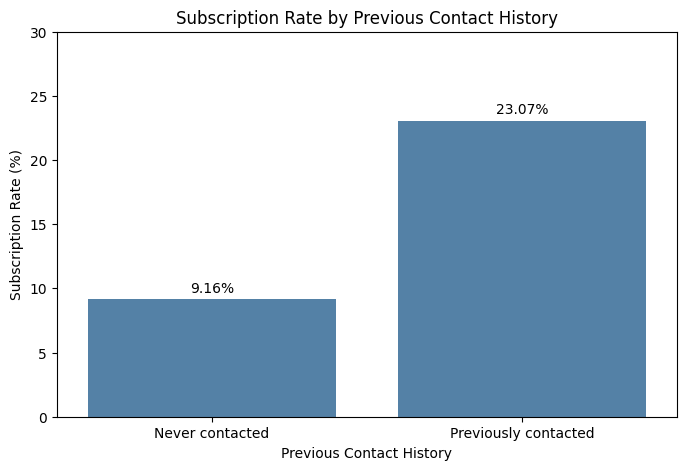

In [21]:

# Visualize subscription rates by previous contact history

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=history_summary.reset_index(),
    x="previous_contact",
    y="subscription_rate",
    color="steelblue"
)

plt.title("Subscription Rate by Previous Contact History")
plt.xlabel("Previous Contact History")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 30)

# Add subscription rate labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.show()


In [22]:

# Compare subscription rates by previous campaign outcome

outcome_summary = (
    clean_bankdf.groupby("previous_outcome_group")["subscribed"]
    .agg(["count", "sum", "mean"])
)

# Convert subscription proportions to percentages
outcome_summary["subscription_rate"] = (
    outcome_summary["mean"] * 100
)

# Sort from highest to lowest subscription rate
outcome_summary = outcome_summary.sort_values(
    by="subscription_rate",
    ascending=False
)

display(outcome_summary)


,count,sum,mean,subscription_rate
previous_outcome_group,,,,
success,1511,978,0.647253,64.725347
Outcome unknown,5,2,0.400000,40.000000
other,1840,307,0.166848,16.684783
failure,4901,618,0.126097,12.609671
No previous contact,36954,3384,0.091573,9.157331


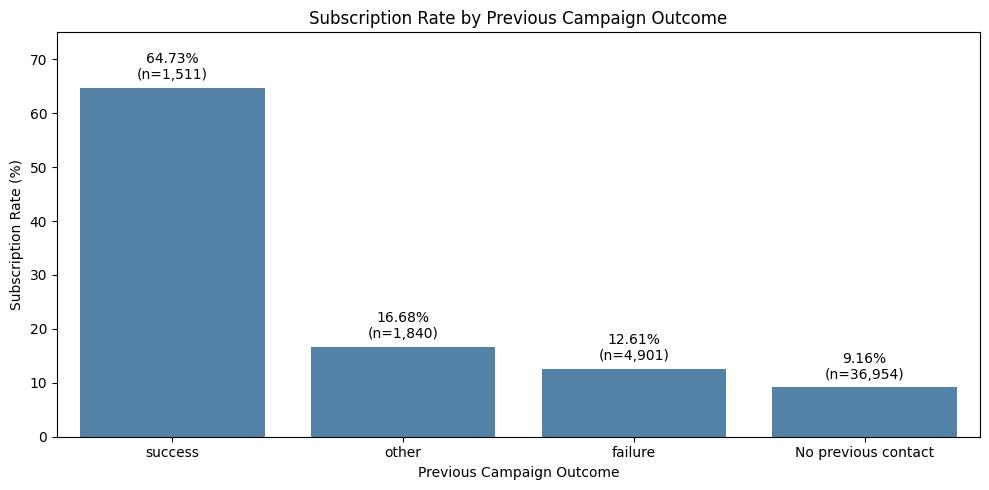

In [23]:

#  Visualize subscription rates by previous campaign outcome

import matplotlib.pyplot as plt
import seaborn as sns

# Exclude the 5-record group from the main visualization only
plot_data = outcome_summary.drop(
    index="Outcome unknown"
).reset_index()

# Create the bar chart
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_data,
    x="previous_outcome_group",
    y="subscription_rate",
    color="steelblue"
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 75)

# Label each bar with rate and sample size
for i, row in plot_data.iterrows():
    ax.text(
        i,
        row["subscription_rate"] + 1,
        f'{row["subscription_rate"]:.2f}%\n(n={int(row["count"]):,})',
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Outcome unknown (n = 5) is excluded from the visualization due to its very small sample size but retained in the dataset.

Finding:
Subscription ratet was 64.73% among customers with a previously successful marketing outcome, compared to only 12.61% among those with a previously unsuccessful outcome.Hitorical marketing outcomes reveal more nuanced differences in subscription rates rather than simply whether a customer had been contacted before.

Current Campaign Frequency Analysis

In [24]:

# Compare subscription rates across campaign frequency groups

campaign_summary = (
    clean_bankdf.groupby(
        "campaign_group",
        observed=True
    )["subscribed"]
    .agg(["count", "sum", "mean"])
)

# Convert mean to percentage
campaign_summary["subscription_rate"] = (
    campaign_summary["mean"] * 100
)

display(campaign_summary)


,count,sum,mean,subscription_rate
campaign_group,,,,
1,17544,2561,0.145976,14.597583
2,12505,1401,0.112035,11.203519
3,5521,618,0.111936,11.193624
4-5,5286,456,0.086266,8.626561
6-10,3159,206,0.065211,6.521051
11+,1196,47,0.039298,3.929766


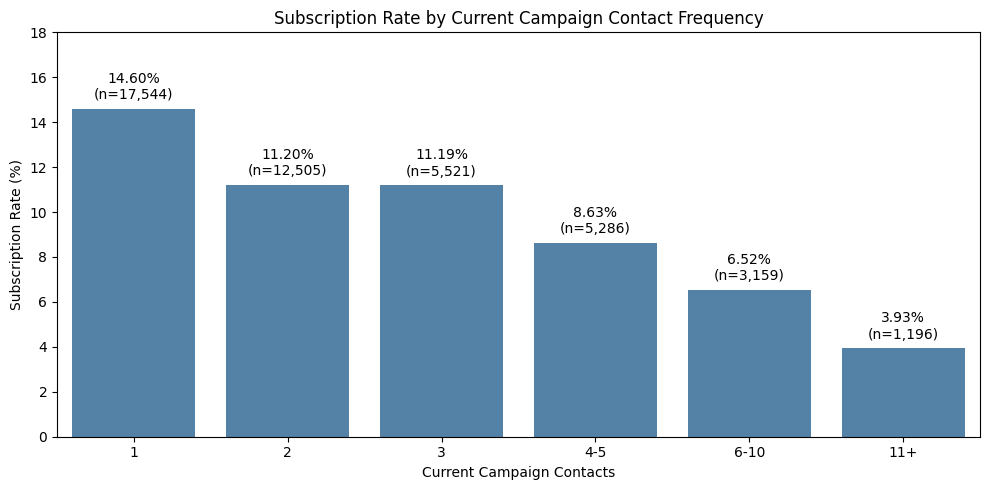

In [25]:

# Visualize subscription rate by current campaign frequency

plot_data = campaign_summary.reset_index()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_data,
    x="campaign_group",
    y="subscription_rate",
    color="steelblue"
)

plt.title("Subscription Rate by Current Campaign Contact Frequency")
plt.xlabel("Current Campaign Contacts")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 18)

# Add subscription rate and sample size above each bar
for i, row in plot_data.iterrows():
    ax.text(
        i,
        row["subscription_rate"] + 0.3,
        f'{row["subscription_rate"]:.2f}%\n(n={int(row["count"]):,})',
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Findings:
1. Subscription rates are lower in higher-contact groups, a difference of 10.67 percentage points across those who were contacted once and contacted over eleven times.
2. Sample sizes are decreasing as the contact frequency increased.

In [26]:
# Interaction Summary for Historical contact and current campaign frequency

# Historical contact x current campaign frequency

interaction_summary = (
    clean_bankdf.groupby(
        ["campaign_group", "previous_contact"],
        observed=True
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert subscription rate to percentages
interaction_summary["subscription_rate"] = (
    interaction_summary["mean"] * 100
)

display(interaction_summary)


,campaign_group,previous_contact,count,sum,mean,subscription_rate
0,1,Never contacted,13529,1523,0.112573,11.257299
1,1,Previously contacted,4015,1038,0.258531,25.853051
2,2,Never contacted,10229,896,0.087594,8.759410
3,2,Previously contacted,2276,505,0.221880,22.188049
4,3,Never contacted,4608,399,0.086589,8.658854
5,3,Previously contacted,913,219,0.239869,23.986857
6,4-5,Never contacted,4605,347,0.075353,7.535288
7,4-5,Previously contacted,681,109,0.160059,16.005874
8,6-10,Never contacted,2811,173,0.061544,6.154393
9,6-10,Previously contacted,348,33,0.094828,9.482759


Findings:
1. Previously contacted groups have higher observed subscription rates, althouh the differences are varied across the groups
2. Historical-contact gap generally narrows at higher contact counts
3. The 11+ category is unreliable for strong conclusions --> only 24 counts but 1 subscribed, the sample size indicates the conclusions tends to be more uncertain

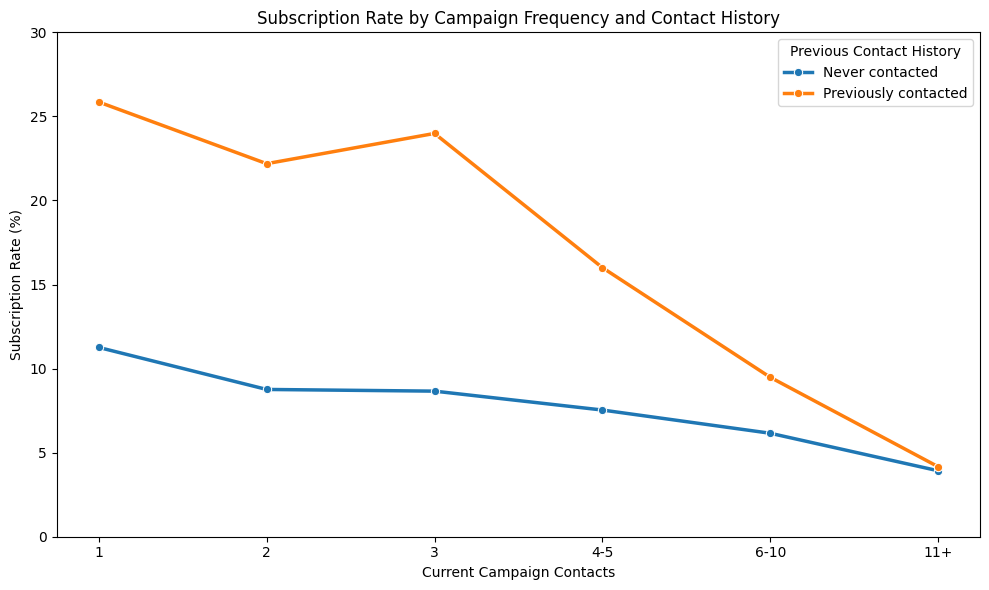

In [27]:
# Visualize historical contact x current campaign frequency

plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=interaction_summary,
    x="campaign_group",
    y="subscription_rate",
    hue="previous_contact",
    marker="o",
    linewidth=2.5
)

plt.title(
    "Subscription Rate by Campaign Frequency and Contact History"
)
plt.xlabel("Current Campaign Contacts")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 30)

plt.legend(title="Previous Contact History")
plt.tight_layout()
plt.show()


In [28]:
# Find out whether the contact frequencies differ across the subscription rates across previously contacted and successful customers?

# Previous campaign outcome x current contact frequency

outcome_campaign_summary = (
    clean_bankdf.groupby(
        ["previous_outcome_group", "campaign_group"],
        observed=True
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert to percentages
outcome_campaign_summary["subscription_rate"] = (
    outcome_campaign_summary["mean"] * 100
)

# Display the summary
display(outcome_campaign_summary)


,previous_outcome_group,campaign_group,count,sum,mean,subscription_rate
0,No previous contact,1,13529,1523,0.112573,11.257299
1,No previous contact,2,10229,896,0.087594,8.759410
2,No previous contact,3,4608,399,0.086589,8.658854
3,No previous contact,4-5,4605,347,0.075353,7.535288
4,No previous contact,6-10,2811,173,0.061544,6.154393
5,No previous contact,11+,1172,46,0.039249,3.924915
6,Outcome unknown,1,2,1,0.500000,50.000000
7,Outcome unknown,3,2,0,0.000000,0.000000
8,Outcome unknown,4-5,1,1,1.000000,100.000000
9,failure,1,2458,343,0.139544,13.954434


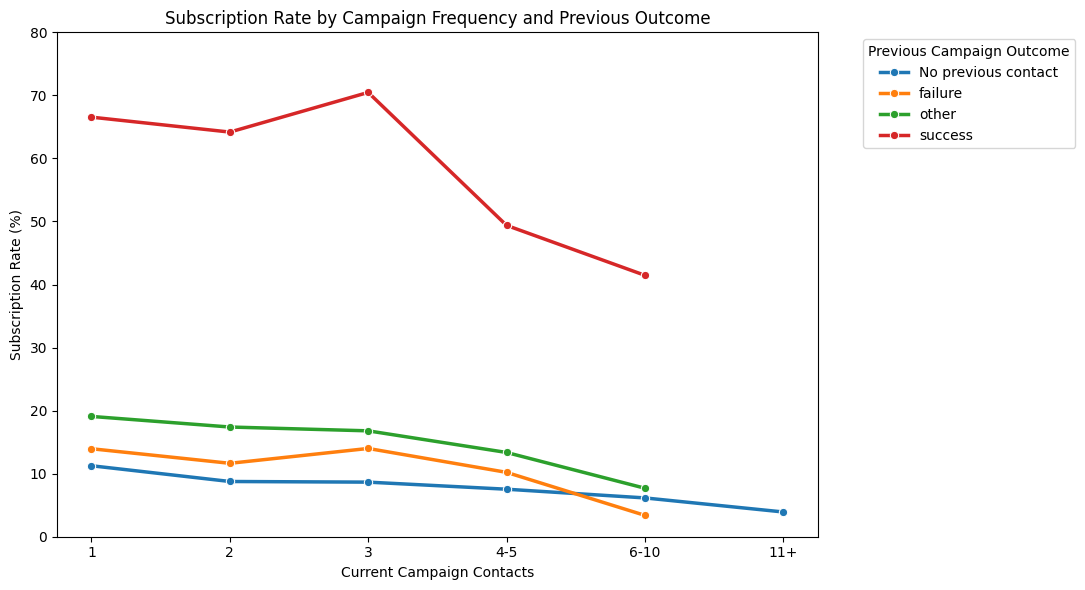

In [29]:

# Visualize previous outcomes across campaign frequency

# Keep the four main historical outcome categories
plot_data = outcome_campaign_summary[
    outcome_campaign_summary["previous_outcome_group"].isin([
        "No previous contact",
        "failure",
        "other",
        "success"
    ])
].copy()

# Exclude group combinations with fewer than 30 observations -> to examine whether customers with different historical marketing outcomes exhibit different subscription rate patterns as the number of contacts in the current campaign increases.
plot_data = plot_data[
    plot_data["count"] >= 30
]

plt.figure(figsize=(11, 6))

ax = sns.lineplot(
    data=plot_data,
    x="campaign_group",
    y="subscription_rate",
    hue="previous_outcome_group",
    marker="o",
    linewidth=2.5
)

plt.title(
    "Subscription Rate by Campaign Frequency and Previous Outcome"
)
plt.xlabel("Current Campaign Contacts")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 80)

plt.legend(
    title="Previous Campaign Outcome",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


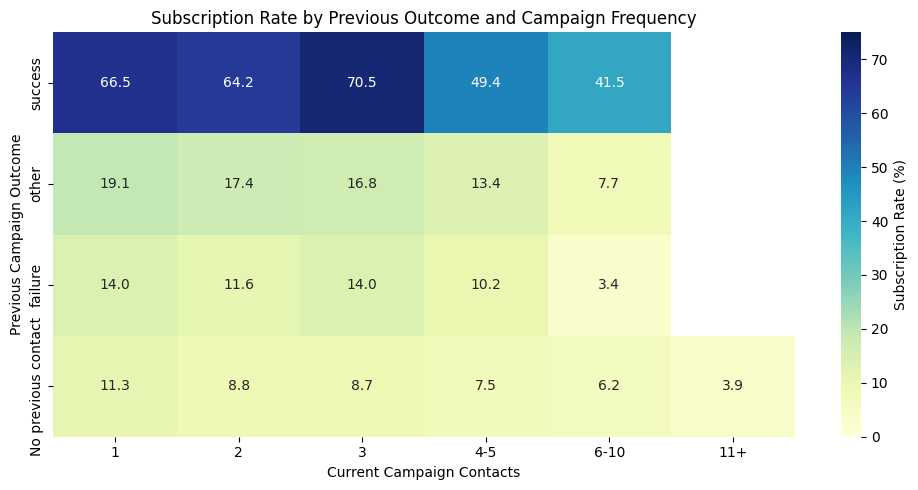

In [45]:

# Heatmap of previous outcome x campaign frequency

heatmap_data = outcome_campaign_summary[
    outcome_campaign_summary["previous_outcome_group"].isin(
        ["No previous contact", "failure", "other", "success"]
    )
].copy()

# Avoid displaying unstable rates from very small groups
heatmap_data.loc[
    heatmap_data["count"] < 30,
    "subscription_rate"
] = np.nan

heatmap_table = heatmap_data.pivot(
    index="previous_outcome_group",
    columns="campaign_group",
    values="subscription_rate"
)

heatmap_table = heatmap_table.reindex(
    ["success", "other", "failure", "No previous contact"]
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=75,
    cbar_kws={"label": "Subscription Rate (%)"}
)

plt.title("Subscription Rate by Previous Outcome and Campaign Frequency")
plt.xlabel("Current Campaign Contacts")
plt.ylabel("Previous Campaign Outcome")
plt.tight_layout()
plt.show()


Cells with fewer than 30 observations are omitted due to unstable estimates.

Findings:
1. Historical Success is associated with much higher subscription rates. Across the range of 1 to 10 contacts in the current campaign, the Previous Success group consistently had substantially higher subscription rates than the other historical outcome groups.
2. Contact-frequency patterns differ across historical outcomes
For the Previous Success group, subscription rates remained relatively high, ranging from approximately 64% to 70% when customers were contacted 1-3 times. However, the subscription rate declined to 49.38% for 4-5 contacts and further decreased to 41.46% for 6-10 contacts. Therefore,the relationship between current campaign contact frequency and subscription rates may differ depending on customers' previous marketing outcomes.

Part 2 of descriptive question - Customer segmentation analysis, whether the patterns remain across different customer bases that were previously contacted?

In [30]:
# Housing segmentation summary, yes = has housing loans and no = no housing loans

#Housing segmentation analysis

housing_summary = (
    clean_bankdf.groupby(
        ["housing", "previous_contact"]
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert to percentages
housing_summary["subscription_rate"] = (
    housing_summary["mean"] * 100
)

display(housing_summary)


,housing,previous_contact,count,sum,mean,subscription_rate
0,no,Never contacted,16966,2100,0.123777,12.377697
1,no,Previously contacted,3115,1254,0.402568,40.256822
2,yes,Never contacted,19988,1284,0.064239,6.423854
3,yes,Previously contacted,5142,651,0.126604,12.660443


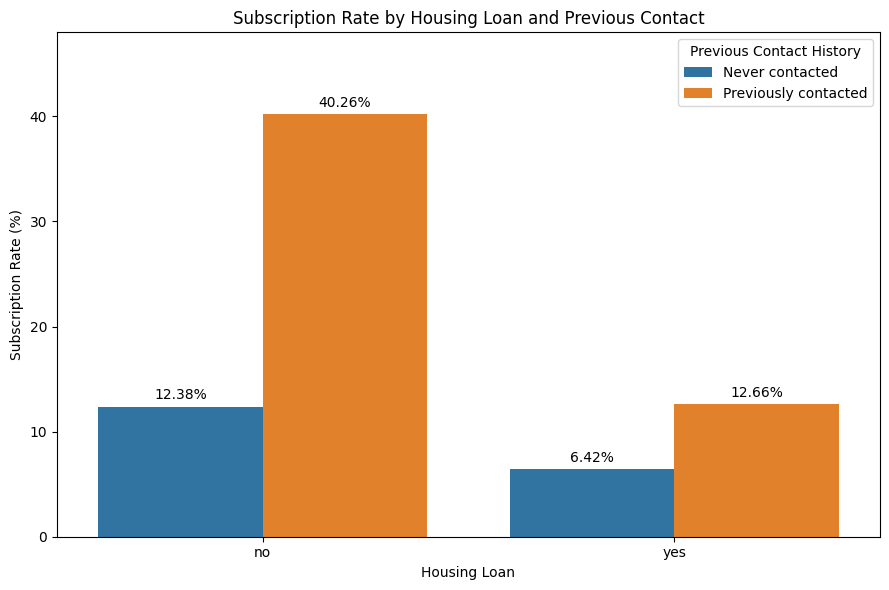

In [31]:

# Visualize housing segmentation

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=housing_summary,
    x="housing",
    y="subscription_rate",
    hue="previous_contact",
    order=["no", "yes"]
)

plt.title("Subscription Rate by Housing Loan and Previous Contact")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 48)

plt.legend(title="Previous Contact History")

# Add subscription rate labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()
plt.show()


Finding:
The relationship between previous contact history and subscription rates varies across housing loan segments, suggesting that customer characteristics should be considered when interpreting historical contact patterns. These descriptive findings identify associations rather than establishing causal effects.

In [32]:
#Does the relationship between current campaign contact frequency and subscription rate differ across housing-loan segments and previous-contact histories?

#Housing x campaign frequency x previous contact

housing_campaign_summary = (
    clean_bankdf.groupby(
        ["housing", "campaign_group", "previous_contact"],
        observed=True
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert subscription proportions into percentages
housing_campaign_summary["subscription_rate"] = (
    housing_campaign_summary["mean"] * 100
)

# Display results
display(housing_campaign_summary)


,housing,campaign_group,previous_contact,count,sum,mean,subscription_rate
0,no,1,Never contacted,5805,963,0.165891,16.589147
1,no,1,Previously contacted,1621,690,0.425663,42.566317
2,no,2,Never contacted,4803,557,0.115969,11.596919
3,no,2,Previously contacted,845,333,0.394083,39.408284
4,no,3,Never contacted,2056,232,0.112840,11.284047
5,no,3,Previously contacted,326,139,0.426380,42.638037
6,no,4-5,Never contacted,2261,216,0.095533,9.553295
7,no,4-5,Previously contacted,216,70,0.324074,32.407407
8,no,6-10,Never contacted,1465,107,0.073038,7.303754
9,no,6-10,Previously contacted,102,21,0.205882,20.588235


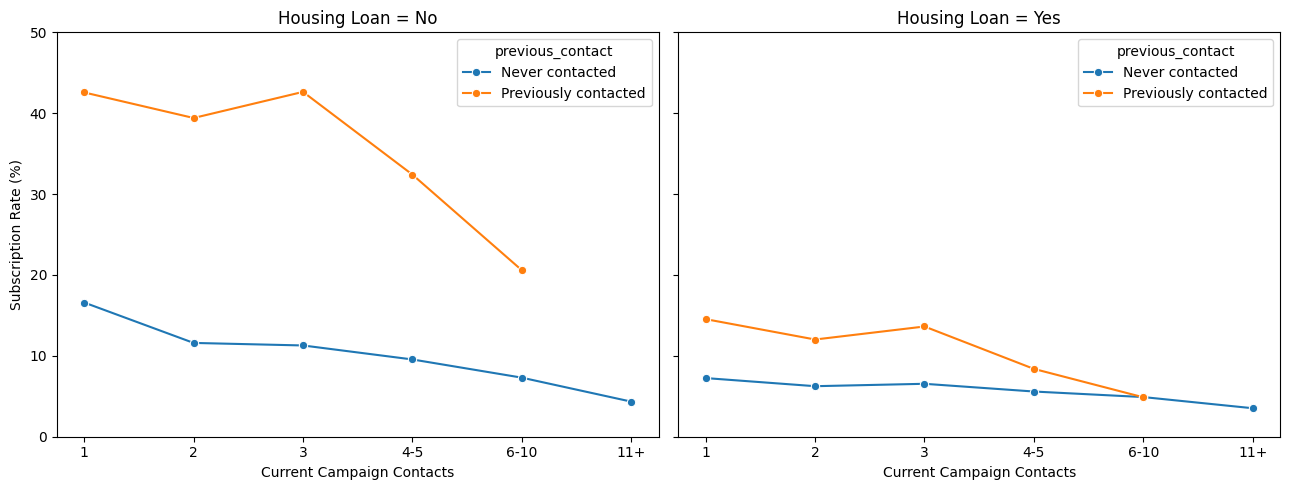

In [48]:
# Housing faceted interaction plot --> it distinguishes the two housing groups, allowing them using the same y-axis, so we could find out whether customers with the same previous contact status and current campaign contact frequency exhibit similar subscription rate patterns across different housing loan segments?

housing_plot = housing_campaign_summary[
    housing_campaign_summary["count"] >= 30
]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True
)

sns.lineplot(
    data=housing_plot[housing_plot["housing"] == "no"],
    x="campaign_group",
    y="subscription_rate",
    hue="previous_contact",
    marker="o",
    ax=axes[0]
)

sns.lineplot(
    data=housing_plot[housing_plot["housing"] == "yes"],
    x="campaign_group",
    y="subscription_rate",
    hue="previous_contact",
    marker="o",
    ax=axes[1]
)

axes[0].set_title("Housing Loan = No")
axes[1].set_title("Housing Loan = Yes")

for ax in axes:
    ax.set_ylim(0, 50)
    ax.set_xlabel("Current Campaign Contacts")
    ax.set_ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()


Even after further segmenting customers by current campaign contact frequency, the magnitude of the differences in subscription rates associated with previous contact status remains substantially different across the two housing loan segments.

In [34]:
#Do previous-contact subscription patterns differ across occupational segments?

#Compare previous contact patterns across job segments

job_summary = (
    clean_bankdf.groupby(
        ["job", "previous_contact"]
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert to percentages
job_summary["subscription_rate"] = (
    job_summary["mean"] * 100
)

# Sort by job and historical contact status
job_summary = job_summary.sort_values(
    by=["job", "previous_contact"]
)

display(job_summary)


,job,previous_contact,count,sum,mean,subscription_rate
0,admin.,Never contacted,4082,382,0.093582,9.358158
1,admin.,Previously contacted,1089,249,0.228650,22.865014
2,blue-collar,Never contacted,8115,524,0.064572,6.457178
3,blue-collar,Previously contacted,1617,184,0.113791,11.379097
4,entrepreneur,Never contacted,1262,96,0.076070,7.606973
5,entrepreneur,Previously contacted,225,27,0.120000,12.000000
6,housemaid,Never contacted,1088,75,0.068934,6.893382
7,housemaid,Previously contacted,152,34,0.223684,22.368421
8,management,Never contacted,7632,779,0.102070,10.207023
9,management,Previously contacted,1826,522,0.285871,28.587076


Findings:
1. Historical contact differences appear across occupational groups, the magnitude of the association between previous contact history and subscription rates varies substantially across occupational groups.
2. Certain occupational groups have higher observed subscription rates -> Previously contacted customers in the Retired, Student, and Unemployed groups exhibited relatively higher subscription rates.
3. Small Sample size conerns in the unkown job category, although the previously contacted group exhibited a relatively high subscription rate of 48.48%, this result should be interpreted cautiously due to its small sample size.
Furthermore, the Unknown category does not represent a clearly identifiable occupational segment that banks can directly target.

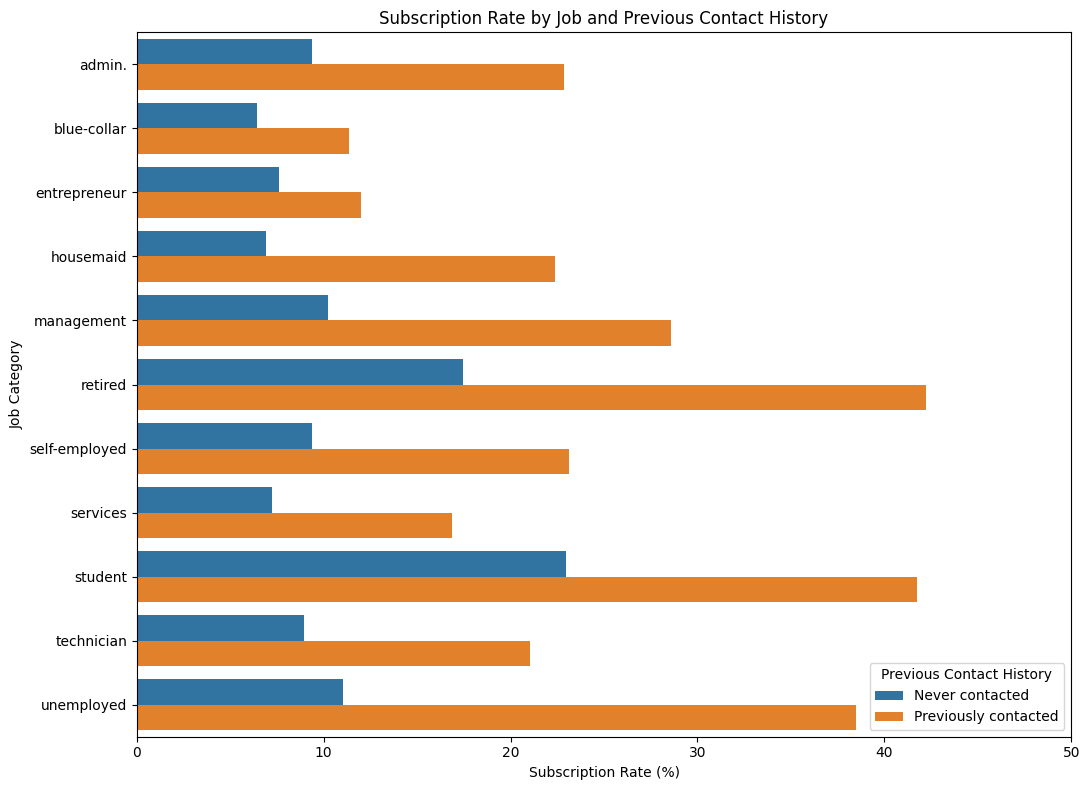

In [35]:
# Visualize job segmentation with grouped horizontal bars -> Are historical-contact subscription patterns consistent across different occupational groups?

# Prepare plotting data
job_plot = job_summary[
    job_summary["job"] != "unknown"
].copy()

plt.figure(figsize=(11, 8))

ax = sns.barplot(
    data=job_plot,
    y="job",
    x="subscription_rate",
    hue="previous_contact",
    orient="h"
)

plt.title("Subscription Rate by Job and Previous Contact History")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")
plt.xlim(0, 50)

plt.legend(
    title="Previous Contact History",
    loc="lower right"
)

plt.tight_layout()
plt.show()


Findings:
1. Historical Contact Patterns Are Consistent in Direction, but Vary in Magnitude, although previously contacted customers consistently exhibit higher subscription rates across occupational groups, the magnitude of the difference varies substantially by occupation.
2. Job Segmentation Supports Earlier Findings from Housing Loan Segmentation, Customer Heterogeneity, suggesting that the relationship between previous contact history and subscription rates differs across customer segments.
3. Limitations of the Job Segmentation Analysis -> while this analysis provides additional insights into differences across occupational groups, it cannot establish whether the observed patterns remain consistent across different levels of current campaign contact frequency.The earlier Housing Loan Faceted Plot provides a more comprehensive multivariable segmentation analysis by incorporating current campaign contact frequency alongside previous contact status and housing loan status.

Reliability and Robustness Checks

In [36]:
#Changing the grouping of campaign contacts, do the main subscription-rate patterns remain similar?

#Alternative campaign frequency grouping

clean_bankdf["campaign_group_alt"] = pd.cut(
    clean_bankdf["campaign"],
    bins=[0, 1, 3, 5, np.inf],
    labels=["1", "2-3", "4-5", "6+"]
)

# Check the number of observations in each new group
print(
    clean_bankdf["campaign_group_alt"]
    .value_counts()
    .sort_index()
)

# Check whether any records were excluded
print(
    "Missing alternative groups:",
    clean_bankdf["campaign_group_alt"].isna().sum()
)


campaign_group_alt
1      17544
2-3    18026
4-5     5286
6+      4355
Name: count, dtype: int64
Missing alternative groups: 0


In [37]:
#Does this pattern remain similar when campaign contacts are grouped differently?

#Check interaction patterns using alternative campaign groups

alt_interaction_summary = (
    clean_bankdf.groupby(
        ["campaign_group_alt", "previous_contact"],
        observed=True
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert subscription proportion to percentage
alt_interaction_summary["subscription_rate"] = (
    alt_interaction_summary["mean"] * 100
)

display(alt_interaction_summary)


,campaign_group_alt,previous_contact,count,sum,mean,subscription_rate
0,1,Never contacted,13529,1523,0.112573,11.257299
1,1,Previously contacted,4015,1038,0.258531,25.853051
2,2-3,Never contacted,14837,1295,0.087282,8.728180
3,2-3,Previously contacted,3189,724,0.227030,22.703042
4,4-5,Never contacted,4605,347,0.075353,7.535288
5,4-5,Previously contacted,681,109,0.160059,16.005874
6,6+,Never contacted,3983,219,0.054984,5.498368
7,6+,Previously contacted,372,34,0.091398,9.139785


Findings:
1. The overall direction remains consistent
2. The gap generally narrows at higher contact frequencies
3. Alternative binning improves the high-frequency sample size

In [38]:
#Check whether historical outcome composition differs by housing

# Focus on customers with previous campaign contacts
previous_clients = clean_bankdf[
    clean_bankdf["previous"] > 0
].copy()

# Count previous outcome categories within each housing segment
housing_outcome_count = pd.crosstab(
    previous_clients["housing"],
    previous_clients["previous_outcome_group"]
)

# Convert counts to percentages within each housing segment
housing_outcome_percent = pd.crosstab(
    previous_clients["housing"],
    previous_clients["previous_outcome_group"],
    normalize="index"
) * 100

print("Counts:")
display(housing_outcome_count)

print("Row percentages:")
display(housing_outcome_percent.round(2))


Counts:


previous_outcome_group,Outcome unknown,failure,other,success
housing,,,,
no,3,1431,641,1040
yes,2,3470,1199,471


Row percentages:


previous_outcome_group,Outcome unknown,failure,other,success
housing,,,,
no,0.10,45.94,20.58,33.39
yes,0.04,67.48,23.32,9.16


In [39]:
#Compare housing segments within the same previous outcome

housing_outcome_rate = (
    previous_clients.groupby(
        ["previous_outcome_group", "housing"]
    )["subscribed"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Convert proportions to percentages
housing_outcome_rate["subscription_rate"] = (
    housing_outcome_rate["mean"] * 100
)

# Exclude very small unknown-outcome groups from the main comparison
housing_outcome_rate_main = housing_outcome_rate[
    housing_outcome_rate["previous_outcome_group"] != "Outcome unknown"
].copy()

display(housing_outcome_rate_main)


,previous_outcome_group,housing,count,sum,mean,subscription_rate
2,failure,no,1431,330,0.230608,23.060797
3,failure,yes,3470,288,0.082997,8.299712
4,other,no,641,194,0.302652,30.265211
5,other,yes,1199,113,0.094245,9.424520
6,success,no,1040,729,0.700962,70.096154
7,success,yes,471,249,0.528662,52.866242


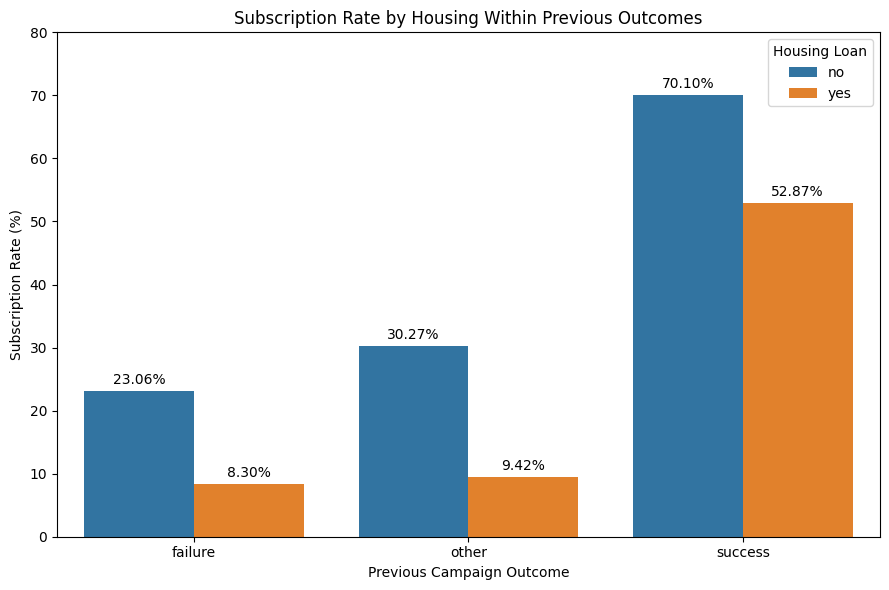

In [40]:

# Visualize housing differences within previous outcomes

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=housing_outcome_rate_main,
    x="previous_outcome_group",
    y="subscription_rate",
    hue="housing",
    order=["failure", "other", "success"],
    hue_order=["no", "yes"]
)

plt.title("Subscription Rate by Housing Within Previous Outcomes")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 80)

plt.legend(title="Housing Loan")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()
plt.show()


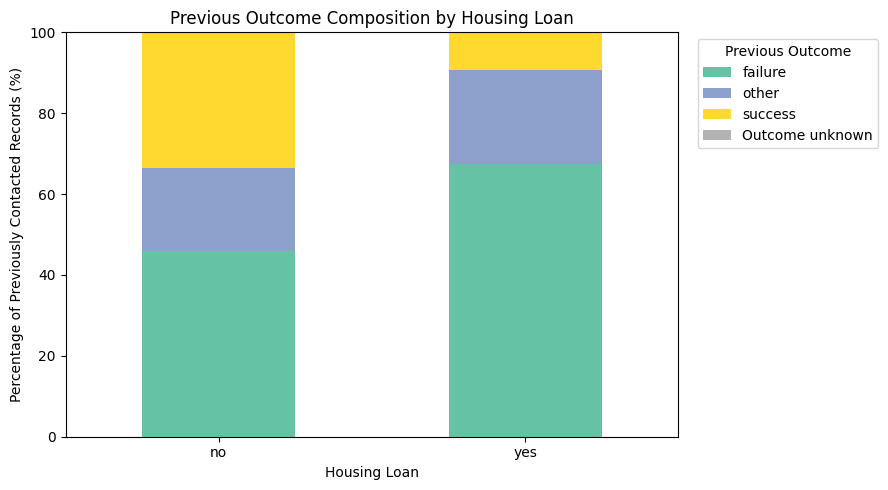

In [46]:
# 100% stacked bar chart for historical outcome composition

plot_data = housing_outcome_percent[
    ["failure", "other", "success", "Outcome unknown"]
]

ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)

plt.title("Previous Outcome Composition by Housing Loan")
plt.xlabel("Housing Loan")
plt.ylabel("Percentage of Previously Contacted Records (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Previous Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


Findings:
1. Housing differences persist within the same historical outcome
2. Historical outcome composition cannot fully explain the observed housing differences


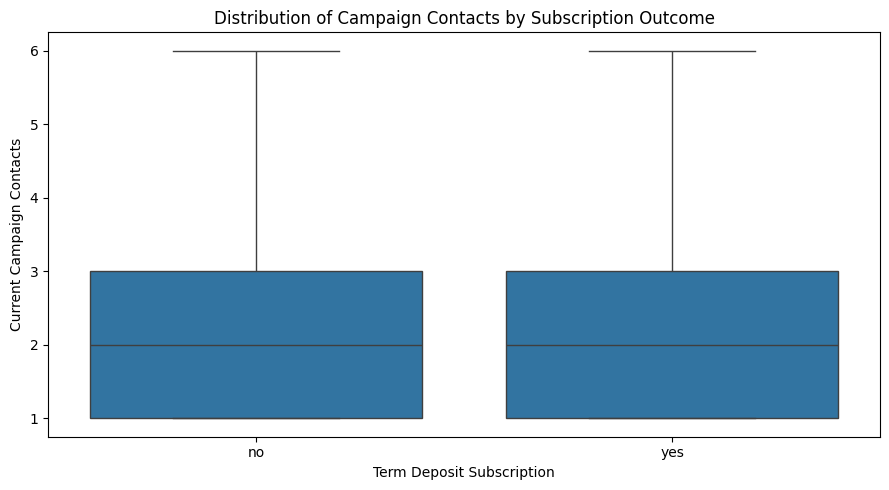

In [44]:

# Compare campaign contact distributions by subscription outcome

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clean_bankdf,
    x="y",
    y="campaign",
    order=["no", "yes"],
    showfliers=False
)

plt.title("Distribution of Campaign Contacts by Subscription Outcome")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Current Campaign Contacts")

plt.tight_layout()
plt.show()


Final Evaluation

In [43]:

# Calculate confidence intervals for subscription rates

from statsmodels.stats.proportion import proportion_confint

# Use the previous outcome x campaign frequency summary
ci_summary = outcome_campaign_summary.copy()

# Calculate Wilson 95% confidence intervals
lower, upper = proportion_confint(
    count=ci_summary["sum"],
    nobs=ci_summary["count"],
    alpha=0.05,
    method="wilson"
)

ci_summary["lower_95"] = lower * 100
ci_summary["upper_95"] = upper * 100

# Focus on the success category
success_ci = ci_summary[
    ci_summary["previous_outcome_group"] == "success"
][[
    "campaign_group",
    "count",
    "subscription_rate",
    "lower_95",
    "upper_95"
]]

display(success_ci.round(2))


,campaign_group,count,subscription_rate,lower_95,upper_95
21,1,837,66.55,63.28,69.66
22,2,402,64.18,59.38,68.71
23,3,149,70.47,62.70,77.21
24,4-5,81,49.38,38.77,60.05
25,6-10,41,41.46,27.76,56.63
26,11+,1,100.00,20.65,100.00


Findings:
1. Smaller samples generally have wider confidence intervals, subscription rate estimates become less precise in subgroups with higher contact frequencies and smaller sample sizes.
2. We should not interpret the 100% literally, the Previous Success and Campaign 11+ subgroup contains only one observation, which resulted in a successful subscription.
Therefore, the observed subscription rate of 100% does not imply that the true subscription probability for this subgroup is 100%.
Given the extremely limited sample size, this estimate is highly uncertain.
This also supports the decision to exclude this subgroup from the main interaction plot to avoid potentially misleading interpretations.
3. The 95% confidence intervals reflect the sampling uncertainty associated with estimated subscription rates.because the Bank Marketing dataset is observational rather than experimental, and individual observations may not be fully independent, confidence intervals cannot account for potential selection bias or confounding factors.

Final Business implications
1. Historical campaign outcomes may provide more useful targeting information than previous-contact status alone.
2. A uniform customer-contact strategy may overlook substantial heterogeneity.
3. High-contact groups warrant closer review.